#### Phase 4 - SVM on HOG Features

Loads what `src/train_svm.py` produced (`models/svm*.pkl`, `results/svm/`). Nothing is retrained here.

Two SVMs share the same HOG features: a **reference** model trained on tight digit crops, and the **deployed** model trained on equal-width strips of the counter, the input it sees at inference.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from train_svm import evaluation_table, equal_width_strips, NUM_DIGITS
from parse import load_all_annotations

np.random.seed(CONFIG["seed"])

#### 1. Grid search (`results/svm/svm_metrics.json`)


In [2]:
with open(resolve_path(CONFIG["paths"]["svm_metrics"])) as f:
    metrics = json.load(f)

for source, v in metrics["variants"].items():
    print(f"--- {source} ({v['role']}) - grid search, selection on validation split")
    print(pd.DataFrame(v["grid_search"]["log"]).to_string(index=False))
    print(f"best: {v['grid_search']['best_params']} "
          f"(val per-digit accuracy {v['grid_search']['best_val_per_digit_accuracy']:.4f})\n")

ref = metrics["variants"]["digit_crops"]["evaluation"]["testing"]["ground_truth_digit_crops"]
print(f"Reference SVM on ground-truth test digit crops: per-digit {ref['per_digit_accuracy']:.4f}, "
      f"full-sequence {ref['full_sequence_accuracy']:.4f}")

--- digit_crops (reference) - grid search, selection on validation split
    C  gamma  val_per_digit_accuracy
  0.1  scale                  0.9190
  0.1   0.01                  0.6755
  0.1  0.001                  0.9200
  1.0  scale                  0.9540
  1.0   0.01                  0.9080
  1.0  0.001                  0.9445
 10.0  scale                  0.9550
 10.0   0.01                  0.9135
 10.0  0.001                  0.9460
100.0  scale                  0.9550
100.0   0.01                  0.9135
100.0  0.001                  0.9455
best: {'C': 10, 'gamma': 'scale'} (val per-digit accuracy 0.9550)

--- counter_strips (deployed) - grid search, selection on validation split
    C  gamma  val_per_digit_accuracy
  0.1  scale                  0.7195
  0.1   0.01                  0.1730
  0.1  0.001                  0.6735
  1.0  scale                  0.8300
  1.0   0.01                  0.7790
  1.0  0.001                  0.7930
 10.0  scale                  0.8420
 10.0   

#### 2. HOG visualisation

Each 32×32 digit image (tight crop or strip) becomes a 324-value HOG vector: 9 orientation bins ×
2×2 cells per block × 3×3 blocks. The panels below compute it step by step on one training strip,
ending with the same `skimage.feature.hog` view used in the Inspector's Capture tab.


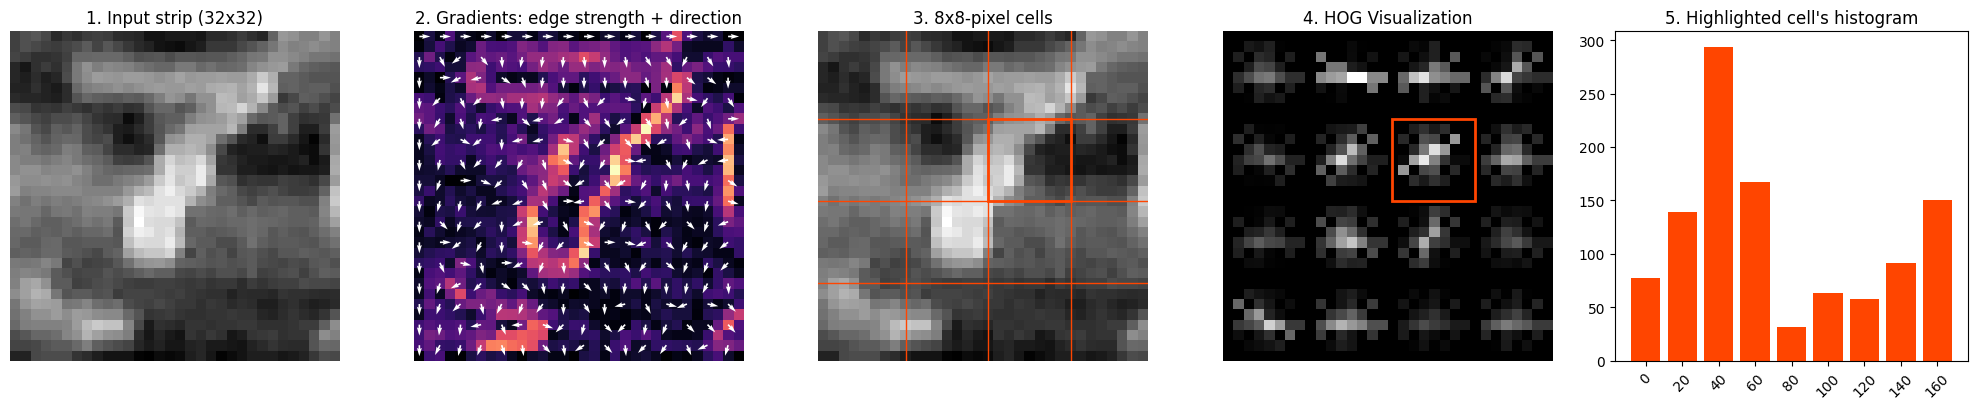

feature vector length: 324  (9 orientations x 2x2 cells/block x 3x3 blocks)


In [3]:
from skimage.feature import hog as hog_fn

digit_size = tuple(CONFIG["image_sizes"]["digit_crop"])
svm_cfg = CONFIG["svm"]

name = "meter0079"  # To change
counter = cv2.imread(str(resolve_path(CONFIG["paths"]["recognition_dir"]) / "training" / "counters" / f"{name}.jpg"))
strip = equal_width_strips(counter, digit_size)[3]  # To change - digit position 4 ("7")
img = cv2.cvtColor(strip, cv2.COLOR_BGR2GRAY).astype(np.float64)

orientations = svm_cfg["hog_orientations"]
ppc = tuple(svm_cfg["hog_pixels_per_cell"])
cpb = tuple(svm_cfg["hog_cells_per_block"])
cell = ppc[0]

g_row = np.zeros_like(img); g_col = np.zeros_like(img)
g_row[1:-1, :] = img[2:, :] - img[:-2, :]
g_col[:, 1:-1] = img[:, 2:] - img[:, :-2]
magnitude = np.hypot(g_row, g_col)
orientation = np.rad2deg(np.arctan2(g_row, g_col)) % 180

features, hog_vis = hog_fn(img, orientations=orientations, pixels_per_cell=ppc,
                            cells_per_block=cpb, visualize=True)

# pick the cell with the most gradient energy (a fixed cell may land on background)
n_rows, n_cols = img.shape[0] // cell, img.shape[1] // cell
cell_energy = np.array([[magnitude[r*cell:(r+1)*cell, c*cell:(c+1)*cell].sum()
                          for c in range(n_cols)] for r in range(n_rows)])
cr, cc = np.unravel_index(np.argmax(cell_energy), cell_energy.shape)
r0, c0 = cr * cell, cc * cell
bin_edges = np.linspace(0, 180, orientations + 1)
hist, _ = np.histogram(orientation[r0:r0+cell, c0:c0+cell], bins=bin_edges,
                        weights=magnitude[r0:r0+cell, c0:c0+cell])

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"1. Input strip ({img.shape[1]}x{img.shape[0]})")
axes[1].imshow(magnitude, cmap="magma")
ys, xs = np.mgrid[0:img.shape[0]:2, 0:img.shape[1]:2]
axes[1].quiver(xs, ys, np.cos(np.deg2rad(orientation[::2, ::2])), -np.sin(np.deg2rad(orientation[::2, ::2])),
               color="white", scale=30, width=0.005)
axes[1].set_title("2. Gradients: edge strength + direction")
axes[2].imshow(img, cmap="gray")
for k in range(1, img.shape[1] // cell):
    axes[2].axhline(k * cell, color="orangered", lw=1); axes[2].axvline(k * cell, color="orangered", lw=1)
axes[2].add_patch(plt.Rectangle((c0, r0), cell, cell, fill=False, edgecolor="orangered", lw=2))
axes[2].set_title(f"3. {ppc[0]}x{ppc[1]}-pixel cells")
axes[3].imshow(hog_vis, cmap="gray")
axes[3].add_patch(plt.Rectangle((c0, r0), cell, cell, fill=False, edgecolor="orangered", lw=2))
axes[3].set_title("4. HOG Visualization")
axes[4].bar([str(int(b)) for b in bin_edges[:-1]], hist, color="orangered")
axes[4].set_title("5. Highlighted cell's histogram"); axes[4].tick_params(axis="x", rotation=45)
for ax in axes[:4]:
    ax.axis("off")
fig.tight_layout()
plt.show()

print(f"feature vector length: {len(features)}  ({orientations} orientations x {cpb[0]}x{cpb[1]} cells/block x "
      f"{(img.shape[0]//cell - cpb[0] + 1)}x{(img.shape[1]//cell - cpb[1] + 1)} blocks)")


#### 3. What the classifier is trained on matters more than how the counter is cut

Rows: what the SVM was trained on. Columns: what it is scored on (test split). Detector
misses count as wrong readings.


    trained on      role                       evaluated on  per-digit  full-sequence
   digit_crops reference           ground-truth digit crops     0.9540         0.8263
   digit_crops reference        ground-truth counter strips     0.4973         0.1613
   digit_crops reference        detector crops, equal-width     0.4906         0.1325
   digit_crops reference detector crops, projection-profile     0.4291         0.1275
counter_strips  deployed           ground-truth digit crops     0.8695         0.5687
counter_strips  deployed        ground-truth counter strips     0.8528         0.5363
counter_strips  deployed        detector crops, equal-width     0.8218         0.5038
counter_strips  deployed detector crops, projection-profile     0.7054         0.3137


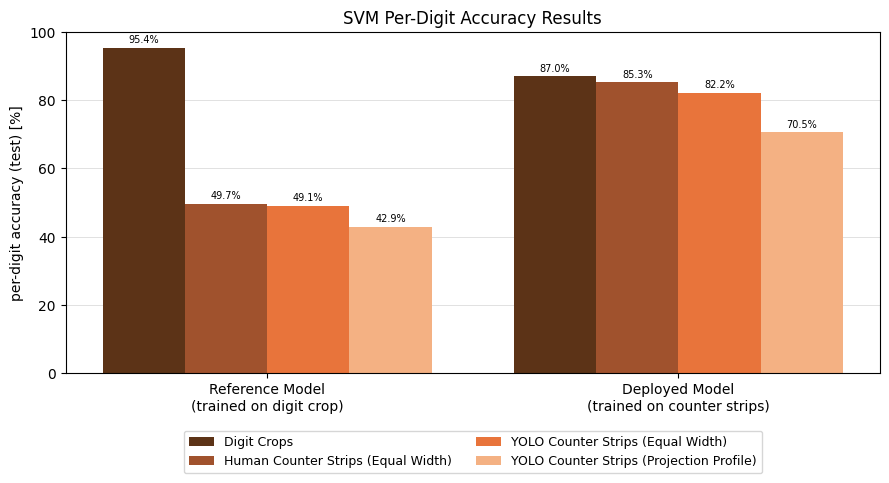


Segmentation used downstream: equal_width (selected on validation)
Reason: equal-width strips matched or beat projection-profile cutting on the validation split, consistent with the near-uniform digit spacing on these mechanical counters


In [4]:
table = pd.DataFrame(evaluation_table(metrics))
print(table.to_string(index=False))

pivot = table.pivot(index="evaluated on", columns="trained on", values="per-digit")
row_order = ["ground-truth digit crops", "ground-truth counter strips",
             "detector crops, equal-width", "detector crops, projection-profile"]
pivot = pivot.reindex(row_order)

test_labels = ["Digit Crops", "Human Counter Strips (Equal Width)",
               "YOLO Counter Strips (Equal Width)", "YOLO Counter Strips (Projection Profile)"]
model_labels = ["Reference Model\n(trained on digit crop)", "Deployed Model\n(trained on counter strips)"]
model_cols = ["digit_crops", "counter_strips"]
colors = ["#5C3317", "#A0522D", "#E8743B", "#F4B183"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(model_cols))  # 2 model groups on the x-axis
n_tests = len(row_order)
width = 0.8 / n_tests

for i, (row_name, label, color) in enumerate(zip(row_order, test_labels, colors)):
    values = [pivot.loc[row_name, col] * 100 for col in model_cols]
    offset = (i - (n_tests - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=7, padding=2)

ax.set_axisbelow(True)
ax.grid(axis="y", color="lightgray", linewidth=0.7, alpha=0.7)
ax.set_xticks(x); ax.set_xticklabels(model_labels)
ax.set_ylim(0, 100); ax.set_ylabel("per-digit accuracy (test) [%]")
ax.set_title("SVM Per-Digit Accuracy Results")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

choice = metrics["segmentation_choice"]
print(f"\nSegmentation used downstream: {choice['chosen']} (selected on {choice['selected_on']})")
print(f"Reason: {choice['reason']}")

**Observation:** The reference SVM reads tight crops well but drops to about half the digits on
strips, whether the strips come from the ground-truth counter or the detector's, so the detector is
not the cause. A strip is wider and off-centre, with drum edges and parts of the neighbouring digits,
so its HOG features differ from a tight crop's: the model was trained on one kind of input and tested
on another. Training the deployed model on strips fixes most of this. The remaining gap between the
tight-crop and strip results is the cost of having no digit boxes at inference.

Equal-width strips were chosen over projection-profile cutting on the validation split: the gaps
between drums are narrow and often as dark as the digits, so searching for gaps is less reliable than
assuming even spacing.


#### 3b. Where the equal-width cuts land on a YOLO crop

The detector is run on one raw photo. The **ground-truth digit boxes** (green) and the **equal-width
cut lines** (red) are drawn on the same 400×106 crop, so the plot shows the input the deployed SVM
receives.

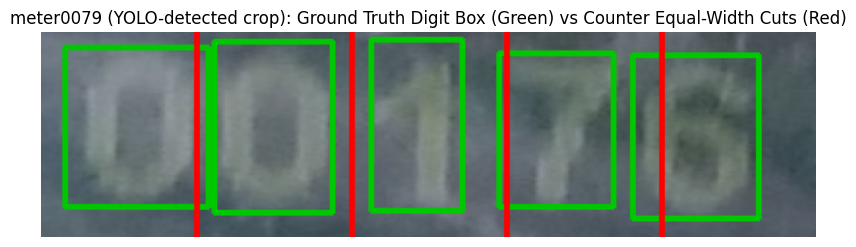

true reading: 00176  (detector confidence 0.836)
equal-width cut x-positions:      [80, 160, 240, 320]
digit box x-ranges (crop coords): [(12, 86), (89, 150), (170, 217), (236, 295), (305, 370)]


In [5]:
from ultralytics import YOLO

basename = "meter0079"  # To change - any image in data/raw/{training,validation,testing}

ann = load_all_annotations()
ann["basename"] = ann["filename"].str.rsplit(".", n=1).str[0]
row = ann.set_index("basename").loc[basename]
digit_bboxes = row["digit_bboxes"]  # ground truth, raw-image pixels
image_path = resolve_path(row["image_path"])

yolo = YOLO(str(resolve_path(CONFIG["paths"]["yolo_weights"])))
result = yolo.predict(source=str(image_path), conf=0.25, verbose=False)[0]
if len(result.boxes) == 0:
    raise RuntimeError(f"YOLO found no counter in {basename} - pick another image")
best = int(np.argmax(result.boxes.conf.cpu().numpy()))
x1, y1, x2, y2 = result.boxes.xyxy[best].cpu().numpy()
conf = float(result.boxes.conf[best])

img = cv2.imread(str(image_path))
px, py = max(0, int(x1)), max(0, int(y1))
x2, y2 = min(img.shape[1], int(x2)), min(img.shape[0], int(y2))
pw, ph = x2 - px, y2 - py  # detector's predicted counter box, raw-image pixels

crop_w, crop_h = tuple(CONFIG["image_sizes"]["counter_crop"])
crop = cv2.resize(img[py:y2, px:x2], (crop_w, crop_h))  # exactly what predicted_crops.py caches
sx, sy = crop_w / pw, crop_h / ph  # raw-image pixels -> crop coordinates, relative to the detector's own box

overlay = crop.copy()
for dx, dy, dw, dh in digit_bboxes:
    bx0, by0 = int((dx - px) * sx), int((dy - py) * sy)
    bx1, by1 = int((dx + dw - px) * sx), int((dy + dh - py) * sy)
    cv2.rectangle(overlay, (bx0, by0), (bx1, by1), (0, 200, 0), 2)

equal_edges = [int(round(i * crop_w / NUM_DIGITS)) for i in range(1, NUM_DIGITS)]
for x in equal_edges:
    cv2.line(overlay, (x, 0), (x, crop_h - 1), (0, 0, 255), 2)

plt.figure(figsize=(10, 3))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(f"{basename} (YOLO-detected crop): Ground Truth Digit Box (Green) vs Counter Equal-Width Cuts (Red)")
plt.axis("off")
plt.show()

print(f"true reading: {row['reading']}  (detector confidence {conf:.3f})")
print(f"equal-width cut x-positions:      {equal_edges}")
print(f"digit box x-ranges (crop coords): "
      f"{[(int((dx - px) * sx), int((dx + dw - px) * sx)) for dx, dy, dw, dh in digit_bboxes]}")

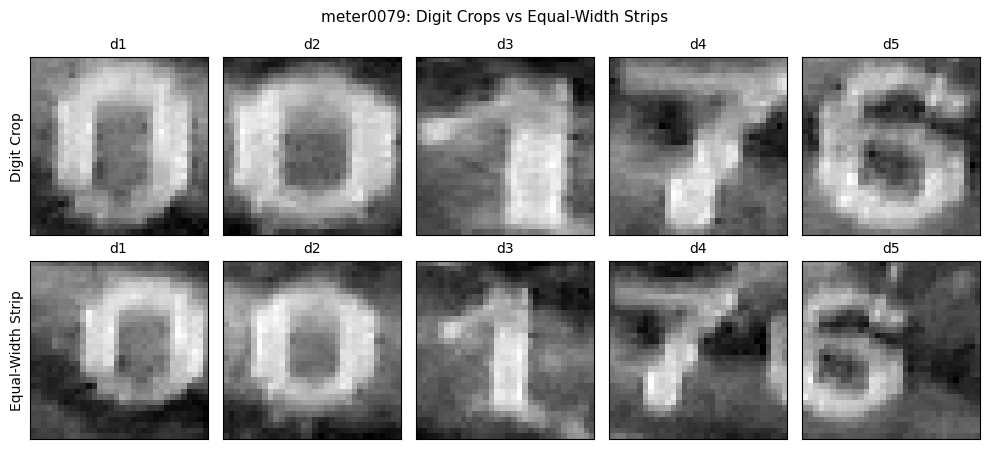

In [6]:
# Cut the same counter both ways, as the SVM receives them: 32x32 grayscale.
# Digit crops come from the ground-truth digit boxes (raw image), strips from the YOLO crop above.
digit_size = tuple(CONFIG["image_sizes"]["digit_crop"])
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

digit_crops = [cv2.resize(gray_img[int(dy):int(dy + dh), int(dx):int(dx + dw)], digit_size)
               for dx, dy, dw, dh in digit_bboxes]
strips = [cv2.cvtColor(s, cv2.COLOR_BGR2GRAY) for s in equal_width_strips(crop, digit_size)]

fig, axes = plt.subplots(2, NUM_DIGITS, figsize=(10, 4.6))
for r, (label, images) in enumerate([("Digit Crop", digit_crops), ("Equal-Width Strip", strips)]):
    for i in range(NUM_DIGITS):
        axes[r, i].imshow(images[i], cmap="gray")
        axes[r, i].set_title(f"d{i + 1}", fontsize=10)
    axes[r, 0].set_ylabel(label, fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"{basename}: Digit Crops vs Equal-Width Strips", fontsize=11)
fig.tight_layout(h_pad=1.5); plt.show()


**Observation:** Same counter, two ways of cutting. A digit crop is centred and fills the frame; a strip is wider than the digit, so the digit comes out smaller, sits off-centre, and picks up drum edges and parts of its neighbours. A model trained only on digit crops has never seen inputs like the strips, which is why the reference SVM drops from about 95% to about 50% per digit on them, and why the deployed model is trained on strips.
